# Lab No 3: Data manipulation, cleaning, and Large Dataset

## 4 Challenges

# Challenge 1

**What happens if you have non-numerical attributes?**

Please extend the `data_description` function to only accept numerical columns and calculate mean and counts. The outcome should be a table with Mean and Counts per Column.

> Tip: Check this function in pandas to filter the numerical values. https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.select_dtypes.html#pandas.DataFrame.select_dtypes
> Here some extra resources of creating function in python https://www.geeksforgeeks.org/python-functions/?ref=lbp


In [ ]:
import pandas as pd 
#extending the data_description() function to produce a table of mean and counts per column
#select_dtypes is used to keep only the numerical columns - used the links as guidence
def data_description(x):
    x = x.select_dtypes(include = 'number')
    stats=pd.DataFrame({'M':x.mean(), 'S':len(x)}) #dataframe construction gives outcome that the challenge wants:table with mean and count per column
    return stats

#if i wanted to test this function:
#create a random df to test
example=pd.DataFrame({'Number':[6,7,8],'Colour':['purple','blue','grey'],'time':[1400,2300,1230]})

data_description(example)

## Description
Summary: Extending the original data_descriptions() function which calculated the mean and count for one column. So to give an output which is a table with mean and counts per column, I extended the function to work with a dataframe with multiple data types and selected onlu nermical values as requested. Tested this by forming a simple df using a dictionary and it gave the correct outpu.

# Challenge 2

Now is your turn to find, read, process and then make a comprehensive descriptive statistics analysis based on the previous resources and others you might need to look at. Create insightful visualizations combining both maps and charts to convey meaningful information about a chosen city.

1. Define a problem within the urban environment and choose a dataset related to urban life or city dynamics. This could include data on crime rates, housing prices, transportation, demographics, or any other urban-related dataset.
2. Get the data ideally using an **API, or web services**. But it's fine if you need to download the data. Describe why you had to use the traditional  method.
3. Work with the data cleaning and pre-processing, check for missing values, convert data types, and perform any other necessary preprocessing steps. You have the code for that in this and previous labs.
4. Use Pandas to calculate descriptive statistics such as `mean`, `median`, `standard deviation`, and other relevant measures. Explore `correlations` between different variables (Include at least one `univariate` and `bivariate` plots) 
6. Create at least one (or more) interactive map to visualize spatial aspects of the data. For example, plot crime rates across different neighbourhoods or visualize housing prices.
7. Complement with additional charts (line charts, bar charts, etc.) to extend the map and highlight key trends or patterns in the data.
8. As always, document well what you are doing and how you use `descriptive statistics and map visualizations` to extract insights from the data.
> You could try explaining any observed patterns, trends, or correlations, whether they are spatial or non-spatial. **Keep in mind** the defined problem and whether your analysis provides the required insights (Your conclusion could be that you need more data or another type of analysis)

In [15]:
#2.1 Define a problem within the urban environment and choose a dataset related to urban life or city dynamics.
    #This could include data on crime rates, housing prices, transportation, demographics, or any other
    #urban-related dataset.

#Thinking of trying a population related urban problem and chose Bristol since i'm familiar with the city, then found the api by searching on google:bristol population API :P
#Inital thought process: to look at the population difference across wards in bristol for two specified years

import requests
import pandas as pd

bristol_pop_url = "https://maps2.bristol.gov.uk/server2/rest/services/ext/ward_profiles/MapServer/34/query?where=1%3D1&outFields=*&outSR=4326&f=json"

#check response before converting to python dictionary
response = requests.get(bristol_pop_url)
response

<Response [200]>

In [16]:
#Convert to python dictionary to be able to inspect the response easier
#then clearing output after running once since response is large
data = response.json()
#data #uncomment to view full json response

In [17]:
#after inspecting the json response i can see that there are several sections:
    #'fieldAliases','fields','features' and i can see that the population counts per ward lie within the 'features' section

#Initially tried: (like from the lab 2)
    #bristol_pop_data=data['features'] 
    #df_bristol_pop=pd.DataFrame(bristol_pop_data)
    #df_bristol_pop.head()
#However this gave a table with each row containing another dictionary with all the pop attributes rather than 
    #the individual columns and after looking again at the json i forgot that it is all nested again within 'attributes'
#Hence i need to extract the individual 'attributes' dictionaries before creating the df - looked back on lab 2 and 
    #thought I'd try to use the same list,for loop and .append() method as we used in the Glasgow traffic example

#Creating the empty list to store the population data we want
bristol_pop_attributes = []

for entry in data['features']:
    pop_attributes = entry['attributes']
    bristol_pop_attributes.append(pop_attributes)

df_bristol_pop = pd.DataFrame(bristol_pop_attributes)
df_bristol_pop.head()

,OBJECTID,WARD_CODE,WARD_NAME,PERIOD,GENDER,ALL_AGES,AGE_0,AGE_1,AGE_2,AGE_3,...,AGE_81,AGE_82,AGE_83,AGE_84,AGE_85,AGE_86,AGE_87,AGE_88,AGE_89,AGE_90_PLUS
0,113,E05010892,Central,2013,All Persons,13000,116,107,106,100,...,22,18,14,18,10,4,9,7,9,13
1,114,E05010893,Clifton,2013,All Persons,12901,77,93,86,72,...,51,35,28,33,26,19,23,16,15,57
2,115,E05010894,Clifton Down,2013,All Persons,11234,100,95,70,67,...,29,21,27,23,12,22,15,14,16,86
3,116,E05010895,Cotham,2013,All Persons,11706,88,64,71,76,...,27,21,12,17,15,21,10,6,4,43
4,117,E05010896,Easton,2013,All Persons,13764,298,309,216,258,...,36,37,27,21,30,32,23,18,23,63


In [45]:
#Should do some quick checks of the df before anything else:
print(df_bristol_pop.shape)
print(df_bristol_pop.columns)
#df_bristol_pop.info() #uncomment if you wish to see the full info() output
#no need to do df_bristol_pop.dtypes as well since dtypes are already displayed in .info()

(1155, 97)
Index(['OBJECTID', 'WARD_CODE', 'WARD_NAME', 'PERIOD', 'GENDER', 'ALL_AGES',
       'AGE_0', 'AGE_1', 'AGE_2', 'AGE_3', 'AGE_4', 'AGE_5', 'AGE_6', 'AGE_7',
       'AGE_8', 'AGE_9', 'AGE_10', 'AGE_11', 'AGE_12', 'AGE_13', 'AGE_14',
       'AGE_15', 'AGE_16', 'AGE_17', 'AGE_18', 'AGE_19', 'AGE_20', 'AGE_21',
       'AGE_22', 'AGE_23', 'AGE_24', 'AGE_25', 'AGE_26', 'AGE_27', 'AGE_28',
       'AGE_29', 'AGE_30', 'AGE_31', 'AGE_32', 'AGE_33', 'AGE_34', 'AGE_35',
       'AGE_36', 'AGE_37', 'AGE_38', 'AGE_39', 'AGE_40', 'AGE_41', 'AGE_42',
       'AGE_43', 'AGE_44', 'AGE_45', 'AGE_46', 'AGE_47', 'AGE_48', 'AGE_49',
       'AGE_50', 'AGE_51', 'AGE_52', 'AGE_53', 'AGE_54', 'AGE_55', 'AGE_56',
       'AGE_57', 'AGE_58', 'AGE_59', 'AGE_60', 'AGE_61', 'AGE_62', 'AGE_63',
       'AGE_64', 'AGE_65', 'AGE_66', 'AGE_67', 'AGE_68', 'AGE_69', 'AGE_70',
       'AGE_71', 'AGE_72', 'AGE_73', 'AGE_74', 'AGE_75', 'AGE_76', 'AGE_77',
       'AGE_78', 'AGE_79', 'AGE_80', 'AGE_81', 'AGE_82', 'AGE_83'

In [22]:
#Next step is to check for any missing values - checking the columns of interest
print("Ward codes missing values:",df_bristol_pop['WARD_CODE'].isna().sum())
print("Ward name missing values:",df_bristol_pop['WARD_NAME'].isna().sum())
print("Period missing values:",df_bristol_pop['PERIOD'].isna().sum())
print("Gender missing values:",df_bristol_pop['GENDER'].isna().sum())
print("All_ages missing values:",df_bristol_pop['ALL_AGES'].isna().sum())

#No missing values found so no need to use .dropna()

Ward codes missing values: 0
Ward name missing values: 0
Period missing values: 0
Gender missing values: 0
All_ages missing values: 0


In [23]:
#Want to decide what two years to compare so need to check which years/periods are included in the data:
#used .unique() function in lab 2:
df_bristol_pop['PERIOD'].unique()

array(['2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020',
       '2021', '2022', '2012'], dtype=object)

In [24]:
#Then though to check what the values inside 'GENDER' and 'WARD_NAME' just for my own reference:
print("values in 'GENDER'",df_bristol_pop['GENDER'].unique())
print("bristol data ward names:", df_bristol_pop['WARD_NAME'].unique())

values in 'GENDER' ['All Persons' 'Male' 'Female']
bristol data ward names: ['Central' 'Clifton' 'Clifton Down' 'Cotham' 'Easton' 'Eastville'
 'Filwood' 'Frome Vale' 'Hartcliffe and Withywood' 'Henbury and Brentry'
 'Hengrove and Whitchurch Park' 'Hillfields' 'Horfield'
 'Hotwells and Harbourside' 'Knowle' 'Lawrence Hill' 'Lockleaze' 'Redland'
 'St George Central' 'St George Troopers Hill' 'St George West'
 'Southmead' 'Southville' 'Stockwood' 'Stoke Bishop'
 'Westbury-on-Trym and Henleaze' 'Windmill Hill' 'Bristol' 'Ashley'
 'Avonmouth and Lawrence Weston' 'Bedminster' 'Bishopston and Ashley Down'
 'Bishopsworth' 'Brislington East' 'Brislington West']


In [25]:
#After looking through the ward names i can see that 'Bristol' is included so should check if this is an overall
    #population record not an individual ward name - i need to check if i need to remove it or not
#filter to just 'WARD_NAME'=='Bristol' then check the first few rows to check
df_bristol_pop[df_bristol_pop['WARD_NAME']=='Bristol'].head()

,OBJECTID,WARD_CODE,WARD_NAME,PERIOD,GENDER,ALL_AGES,AGE_0,AGE_1,AGE_2,AGE_3,...,AGE_81,AGE_82,AGE_83,AGE_84,AGE_85,AGE_86,AGE_87,AGE_88,AGE_89,AGE_90_PLUS
27,140,E06000023,Bristol,2013,All Persons,438984,6533,6594,6176,5940,...,1852,1724,1603,1508,1231,1215,1146,996,880,3393
62,175,E06000023,Bristol,2013,Male,218629,3325,3365,3181,3067,...,767,733,664,611,470,437,406,326,265,929
97,210,E06000023,Bristol,2013,Female,220355,3208,3229,2995,2873,...,1085,991,939,897,761,778,740,670,615,2464
132,245,E06000023,Bristol,2014,All Persons,443834,6337,6317,6364,6001,...,1779,1735,1591,1471,1373,1104,1086,1053,896,3485
167,280,E06000023,Bristol,2014,Male,220872,3207,3244,3264,3063,...,771,719,669,589,544,414,372,369,278,949


In [26]:
#After searching up the bristol ward codes i found that E06000023 is the bristol Local Authority district code 
    #and that the wards within bristol start with E05010XXX from website:https://opendata.westofengland-ca.gov.uk/explore/assets/electoral-wards-divisions-united-kingdom/explore/?vt=rt
#Hence need to remove the city wide summary data to not impact the stats outcomes
#Then since we only want to inspect the whole population by ward we only want to keep All Persons counts

#Using conditional filtering then like from lab 2: using != to remove the 'Bristol' data:
bristol_wards_pop = df_bristol_pop[(df_bristol_pop['GENDER']=='All Persons')&(df_bristol_pop['WARD_NAME']!='Bristol')]

#Then need to inspect the shape of new df:
bristol_wards_pop.shape
#this should give 34 wards*11 years so should have 374 rows if filtered correctly:

(374, 97)

In [27]:
#Still quite a large dataset with 97 columns so next step should be to create a smaller subset with focused attributes
bristol_wards_pop.columns   
#For the interest of the challenge I want to keep the ward code, ward name, the years and the total pop across all ages

keep_cols = ['WARD_CODE','WARD_NAME','PERIOD','ALL_AGES']
bristol_wards_pop=bristol_wards_pop[keep_cols]
print(bristol_wards_pop.shape)
bristol_wards_pop.head()

(374, 4)


,WARD_CODE,WARD_NAME,PERIOD,ALL_AGES
0,E05010892,Central,2013,13000
1,E05010893,Clifton,2013,12901
2,E05010894,Clifton Down,2013,11234
3,E05010895,Cotham,2013,11706
4,E05010896,Easton,2013,13764


In [28]:
#Then i want to select two years of interest - I chose 2012 and 2022 because thats the start and end years of this data
bristol_pop_2012=bristol_wards_pop[bristol_wards_pop['PERIOD']=='2012']
bristol_pop_2022=bristol_wards_pop[bristol_wards_pop['PERIOD']=='2022']

print(bristol_pop_2012.head())
print(bristol_pop_2022.head())

      WARD_CODE                      WARD_NAME PERIOD  ALL_AGES
1043  E05010885                         Ashley   2012     18214
1044  E05010886  Avonmouth and Lawrence Weston   2012     20402
1045  E05010887                     Bedminster   2012     11583
1046  E05010888     Bishopston and Ashley Down   2012     11817
1047  E05010889                   Bishopsworth   2012     10940
     WARD_CODE                      WARD_NAME PERIOD  ALL_AGES
938  E05010885                         Ashley   2022     20826
939  E05010886  Avonmouth and Lawrence Weston   2022     22228
940  E05010887                     Bedminster   2022     12866
941  E05010888     Bishopston and Ashley Down   2022     13156
942  E05010889                   Bishopsworth   2022     12369


In [29]:
#To be able to plot population difference later, need to merge the two

#first check they are the same size before merging:
print("2012 shape:",bristol_pop_2012.shape)
print("2022 shape:",bristol_pop_2022.shape)

#then merging using the SF_Tract_ACS merge from lab 2 as a reference
#defualt inner merge is fine for this merge so no need for how='XXXX'
#merging on both WARD_CODE and WARD_NAME to avoid getting WARD_NAME_x and WARD_NAME_y (for plotting reasons)
bristol_pop_merge=pd.merge(bristol_pop_2012,bristol_pop_2022,on=['WARD_CODE','WARD_NAME'])

2012 shape: (34, 4)
2022 shape: (34, 4)


In [30]:
#checking the merge:
print(bristol_pop_merge.shape)
print(bristol_pop_merge.head())

#checking that there's no missing values
print("Any missing 2012 pop values:",bristol_pop_merge['ALL_AGES_x'].isna().sum())
print("Any missing 2022 pop values:",bristol_pop_merge['ALL_AGES_y'].isna().sum())

(34, 6)
   WARD_CODE                      WARD_NAME PERIOD_x  ALL_AGES_x PERIOD_y  \
0  E05010885                         Ashley     2012       18214     2022   
1  E05010886  Avonmouth and Lawrence Weston     2012       20402     2022   
2  E05010887                     Bedminster     2012       11583     2022   
3  E05010888     Bishopston and Ashley Down     2012       11817     2022   
4  E05010889                   Bishopsworth     2012       10940     2022   

   ALL_AGES_y  
0       20826  
1       22228  
2       12866  
3       13156  
4       12369  
Any missing 2012 pop values: 0
Any missing 2022 pop values: 0


In [31]:
#Since i want to do some population change stats, first need to calculate the differences for each ward
bristol_pop_merge['pop_change']=bristol_pop_merge['ALL_AGES_y']-bristol_pop_merge['ALL_AGES_x']
bristol_pop_merge.head()

,WARD_CODE,WARD_NAME,PERIOD_x,ALL_AGES_x,PERIOD_y,ALL_AGES_y,pop_change
0,E05010885,Ashley,2012,18214,2022,20826,2612
1,E05010886,Avonmouth and Lawrence Weston,2012,20402,2022,22228,1826
2,E05010887,Bedminster,2012,11583,2022,12866,1283
3,E05010888,Bishopston and Ashley Down,2012,11817,2022,13156,1339
4,E05010889,Bishopsworth,2012,10940,2022,12369,1429


In [32]:
#Since the proportion of change is different for each ward I think adding a percentage pop change as well would be good
    #so pop change/total pop *100 as standard
bristol_pop_merge['pop_percentage_change']=(bristol_pop_merge['pop_change']/bristol_pop_merge['ALL_AGES_x'])*100
print(bristol_pop_merge.shape)
bristol_pop_merge.head()

(34, 8)


,WARD_CODE,WARD_NAME,PERIOD_x,ALL_AGES_x,PERIOD_y,ALL_AGES_y,pop_change,pop_percentage_change
0,E05010885,Ashley,2012,18214,2022,20826,2612,14.340617
1,E05010886,Avonmouth and Lawrence Weston,2012,20402,2022,22228,1826,8.950103
2,E05010887,Bedminster,2012,11583,2022,12866,1283,11.076578
3,E05010888,Bishopston and Ashley Down,2012,11817,2022,13156,1339,11.331133
4,E05010889,Bishopsworth,2012,10940,2022,12369,1429,13.062157


In [33]:
#Quickly checking there aren't any missing values from the new columns just calculated:
print("Any missing pop_change values:",bristol_pop_merge['pop_change'].isna().sum())
print("Any missing pop_percentage_change values:",bristol_pop_merge['pop_percentage_change'].isna().sum())

Any missing pop_change values: 0
Any missing pop_percentage_change values: 0


In [34]:
#Then to be thorough, checking if there are any negative values after calculating:
negative_pop_change = bristol_pop_merge[bristol_pop_merge['pop_change'] < 0]
negative_percentage_change = bristol_pop_merge[bristol_pop_merge['pop_percentage_change'] < 0]
print(negative_pop_change.shape,negative_percentage_change.shape)

(0, 8) (0, 8)


In [35]:
#Next is calculating the descriptive stats: mean, median, std etc
#using the lab 3 example: descriptive_stats=subset_listings.describe() as reference:
bristol_pop_stats=bristol_pop_merge[['ALL_AGES_x','ALL_AGES_y','pop_change','pop_percentage_change']].describe()

print("Bristol population statistics:",bristol_pop_stats)

Bristol population statistics:          ALL_AGES_x    ALL_AGES_y   pop_change  pop_percentage_change
count     34.000000     34.000000    34.000000              34.000000
mean   12743.058824  14077.529412  1334.470588              10.812918
std     3366.956336   3856.585193  1308.157882              10.610689
min     4839.000000   6417.000000    95.000000               0.825584
25%    11526.000000  12484.500000   693.000000               5.384589
50%    12262.000000  13335.500000  1183.000000               9.256237
75%    13213.000000  14375.500000  1465.750000              11.810968
max    20402.000000  22228.000000  7747.000000              60.694140


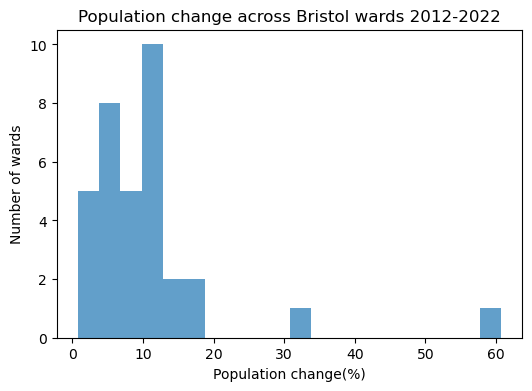

In [36]:
#Next is making the plots which show how the bristol population has changed between 2012 and 2022 across wards

#First thought is to make a histogram to plot the distribution of pop change across wards between 2012 and 2022 
#its technically univariate as its only plotting "frequency" of column 'pop_percentage_change
#Using the lab 3 histogram of Airbnb prices as reference


import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
bristol_pop_merge['pop_percentage_change'].plot(kind='hist', bins=20, alpha=0.7)
plt.title('Population change across Bristol wards 2012-2022')
plt.xlabel('Population change(%)')
plt.ylabel('Number of wards')
plt.show()


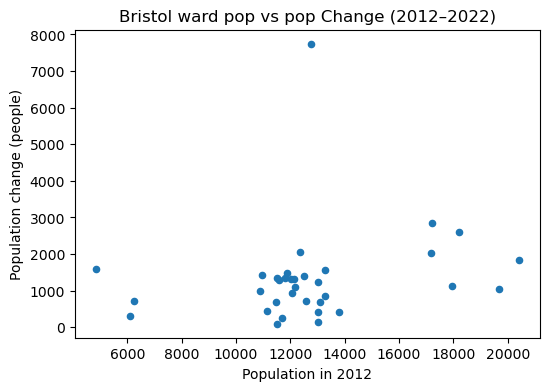

In [37]:
#Next is the bivariate plot and this one i'm comparing 2012 vs 2022 (2 numerical variables) with each point representing a ward and its change in pop
#Helpful because you can see the distribution of pop change from the starting population in 2012 (see which portion of 2012 wards saw the most growth)
#used to help: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html
bristol_pop_merge.plot(kind='scatter',x='ALL_AGES_x',y='pop_change',figsize=(6,4))
plt.title('Bristol ward pop vs pop Change (2012–2022)')
plt.xlabel('Population in 2012')
plt.ylabel('Population change (people)')
plt.show()

In [38]:
#After creating the scatter plot i wanted to find the actual correlation value between initial ward pop and its pop change
#This hasn't been taught in labd yet but i've used it before and used this to help recall:https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html
bristol_pop_corr=bristol_pop_merge[['ALL_AGES_x','pop_change']].corr()
bristol_pop_corr
#Which gives a weak positive correlation result 
    #So wards with larger ops in 2012 don't necessarily experience greater pop increases
    #the weak positive may be influenced due to that one ward which experienced significant growth


,ALL_AGES_x,pop_change
ALL_AGES_x,1.00000,0.20724
pop_change,0.20724,1.00000


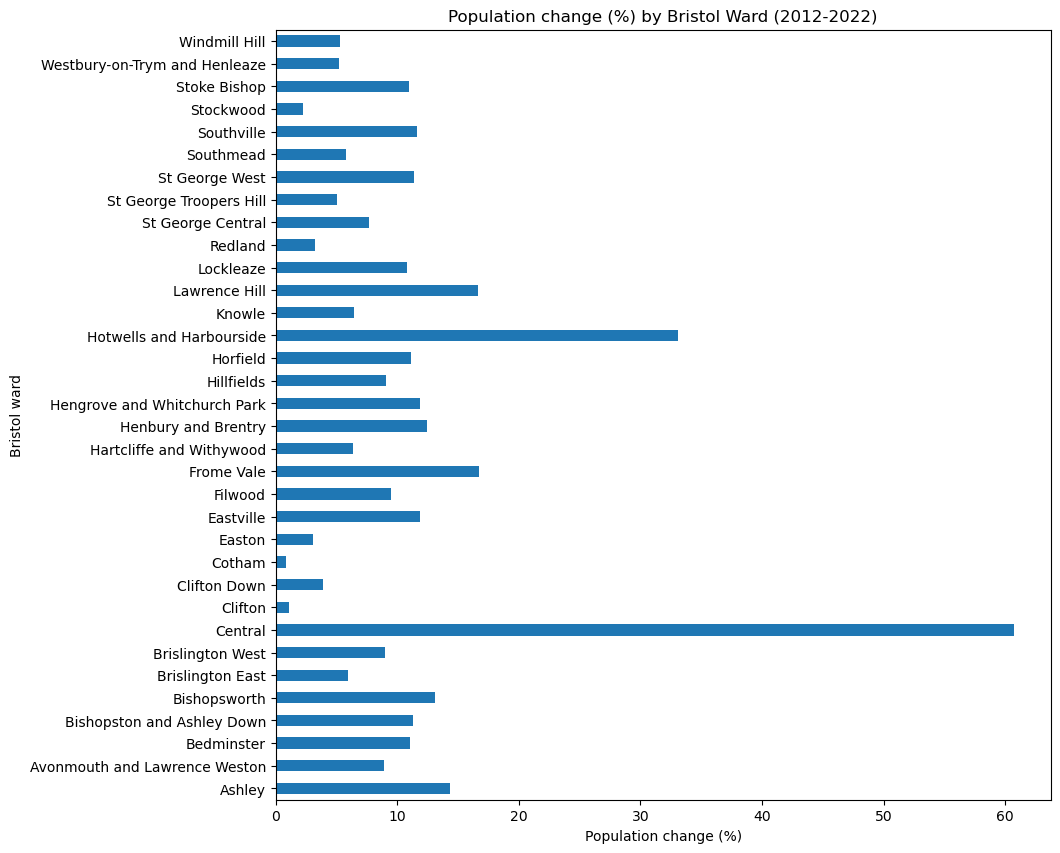

In [39]:
#Next is the multivariate plot, I was thinking of doing a bar chart showing the percentage pop change per ward
#using the pandas plotting e.g. from earlier in lab 3 using kind = 'barh':
bristol_pop_merge.plot(kind='barh',x='WARD_NAME',y='pop_percentage_change',figsize=(10,10),legend=False)
plt.title('Population change (%) by Bristol Ward (2012-2022)')
plt.xlabel('Population change (%)')
plt.ylabel('Bristol ward')
plt.show()

In [40]:
#Next up is to map these population changes across the different wards in Bristol, hence I need the ward boundary data
#Found a ward API from the same website:https://opendata.bristol.gov.uk/datasets/bcc::wards/explore?location=51.470677%2C-2.617042%2C-1.00
bristol_wards_url="https://maps2.bristol.gov.uk/server2/rest/services/ext/ll_boundaries/MapServer/4/query?where=1%3D1&outFields=*&outSR=4326&f=json"
response_wards = requests.get(bristol_wards_url)
response_wards

<Response [200]>

In [41]:
#then converting to python dictionary:
wards_data=response_wards.json()
#wards_data #uncomment if you would like to read the full json response

In [42]:
#Since i'm using the APIs both from the same place then i can copy the attributes extraction again for the wards:
bristol_ward_attributes=[]
for entry in wards_data['features']:
    ward_attributes=entry['attributes']
    bristol_ward_attributes.append(ward_attributes)

In [43]:
#next is creating the dataframe:
df_bristol_wards=pd.DataFrame(bristol_ward_attributes)
print(df_bristol_wards.shape)
print(df_bristol_wards.columns)
df_bristol_wards.head()

(34, 6)
Index(['OBJECTID', 'NAME', 'COUNCILLORS', 'WARD_ID', 'SHAPE.STArea()',
       'SHAPE.STLength()'],
      dtype='object')


,OBJECTID,NAME,COUNCILLORS,WARD_ID,SHAPE.STArea(),SHAPE.STLength()
0,1,Avonmouth & Lawrence Weston,3,E05010886,2.143475e+07,24446.971267
1,2,Stoke Bishop,2,E05010916,5.731849e+06,11049.516431
2,3,Henbury & Brentry,2,E05010901,3.889154e+06,12729.361309
3,4,Bishopsworth,2,E05010889,3.881891e+06,9386.242820
4,5,Hartcliffe & Withywood,3,E05010900,3.609795e+06,10446.140970


In [44]:
import geopandas as gpd
#Looking through the json output, the ward API contains polygon geometries, but my df_bristol_wards that i made
    #only has the attributes because i did entry['attributes'], but to map the population changes per ward i do
    #ideally want to keep the polygon geometry as well - after reviweing the website they do have the GeoJSON API format as well
    #Because of that then i can just skip some steps and use Geopandas directly and also keep the polygons at the same time
#so using new API GEOJSON format with geopandas directly gives:
bristol_wards_geojson_url= "https://maps2.bristol.gov.uk/server2/rest/services/ext/ll_boundaries/MapServer/4/query?where=1%3D1&outFields=*&outSR=4326&f=geojson"
gdf_bristol_wards = gpd.read_file(bristol_wards_geojson_url)
gdf_bristol_wards.head()#this kept the polygon geometry all well!!

,OBJECTID,NAME,COUNCILLORS,WARD_ID,SHAPE.STArea(),SHAPE.STLength(),geometry
0,1,Avonmouth & Lawrence Weston,3,E05010886,2.143475e+07,24446.971267,"POLYGON ((-2.72171 51.50167, -2.72156 51.50166..."
1,2,Stoke Bishop,2,E05010916,5.731849e+06,11049.516431,"POLYGON ((-2.65887 51.48407, -2.65807 51.48337..."
2,3,Henbury & Brentry,2,E05010901,3.889154e+06,12729.361309,"POLYGON ((-2.64717 51.51217, -2.64725 51.51201..."
3,4,Bishopsworth,2,E05010889,3.881891e+06,9386.242820,"POLYGON ((-2.63393 51.42749, -2.63390 51.42729..."
4,5,Hartcliffe & Withywood,3,E05010900,3.609795e+06,10446.140970,"POLYGON ((-2.62874 51.41600, -2.62880 51.41588..."


In [46]:
#Next standard step is inspecting the new gdf:
print(gdf_bristol_wards.shape)
print(gdf_bristol_wards.columns)
print(gdf_bristol_wards.crs)
gdf_bristol_wards.head()

(34, 7)
Index(['OBJECTID', 'NAME', 'COUNCILLORS', 'WARD_ID', 'SHAPE.STArea()',
       'SHAPE.STLength()', 'geometry'],
      dtype='object')
EPSG:4326


,OBJECTID,NAME,COUNCILLORS,WARD_ID,SHAPE.STArea(),SHAPE.STLength(),geometry
0,1,Avonmouth & Lawrence Weston,3,E05010886,2.143475e+07,24446.971267,"POLYGON ((-2.72171 51.50167, -2.72156 51.50166..."
1,2,Stoke Bishop,2,E05010916,5.731849e+06,11049.516431,"POLYGON ((-2.65887 51.48407, -2.65807 51.48337..."
2,3,Henbury & Brentry,2,E05010901,3.889154e+06,12729.361309,"POLYGON ((-2.64717 51.51217, -2.64725 51.51201..."
3,4,Bishopsworth,2,E05010889,3.881891e+06,9386.242820,"POLYGON ((-2.63393 51.42749, -2.63390 51.42729..."
4,5,Hartcliffe & Withywood,3,E05010900,3.609795e+06,10446.140970,"POLYGON ((-2.62874 51.41600, -2.62880 51.41588..."


<Axes: >

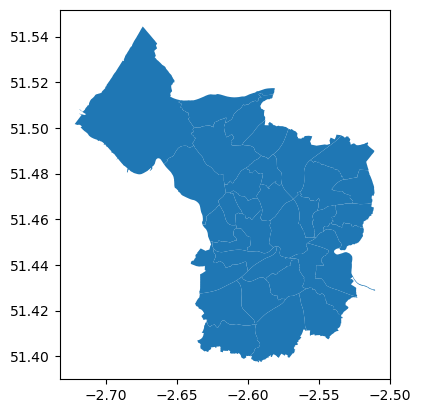

In [47]:
#doing a quick plot again just to check the spatial aspect before merging:
gdf_bristol_wards.plot()

In [48]:
#Using the merge method again taught in the lab 3 workbook with example (SF_Tract_ACS = pd.merge(earnings, bachelors, left_on="UID", right_on="UID"))
#Looking at both the bristol_pop_merge and gdf_bristol_wards, they have columns 'WARD_CODE' and 'WARD_ID' respectively
    #which contain the same data but the column names just slightly differ
#Hence i was thinking of merging left_on 'WARD_ID' and right_on 'WARD_CODE' to fix that
gdf_bristol_pop=pd.merge(gdf_bristol_wards,bristol_pop_merge,left_on='WARD_ID', right_on='WARD_CODE')

#checking merge:
print(gdf_bristol_pop.shape)
print(gdf_bristol_pop.info())
gdf_bristol_pop.head()

(34, 15)
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 34 entries, 0 to 33
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   OBJECTID               34 non-null     int64   
 1   NAME                   34 non-null     object  
 2   COUNCILLORS            34 non-null     int64   
 3   WARD_ID                34 non-null     object  
 4   SHAPE.STArea()         34 non-null     float64 
 5   SHAPE.STLength()       34 non-null     float64 
 6   geometry               34 non-null     geometry
 7   WARD_CODE              34 non-null     object  
 8   WARD_NAME              34 non-null     object  
 9   PERIOD_x               34 non-null     object  
 10  ALL_AGES_x             34 non-null     int64   
 11  PERIOD_y               34 non-null     object  
 12  ALL_AGES_y             34 non-null     int64   
 13  pop_change             34 non-null     int64   
 14  pop_percentage_change  34 n

,OBJECTID,NAME,COUNCILLORS,WARD_ID,SHAPE.STArea(),SHAPE.STLength(),geometry,WARD_CODE,WARD_NAME,PERIOD_x,ALL_AGES_x,PERIOD_y,ALL_AGES_y,pop_change,pop_percentage_change
0,1,Avonmouth & Lawrence Weston,3,E05010886,2.143475e+07,24446.971267,"POLYGON ((-2.72171 51.50167, -2.72156 51.50166...",E05010886,Avonmouth and Lawrence Weston,2012,20402,2022,22228,1826,8.950103
1,2,Stoke Bishop,2,E05010916,5.731849e+06,11049.516431,"POLYGON ((-2.65887 51.48407, -2.65807 51.48337...",E05010916,Stoke Bishop,2012,12017,2022,13337,1320,10.984439
2,3,Henbury & Brentry,2,E05010901,3.889154e+06,12729.361309,"POLYGON ((-2.64717 51.51217, -2.64725 51.51201...",E05010901,Henbury and Brentry,2012,11856,2022,13334,1478,12.466262
3,4,Bishopsworth,2,E05010889,3.881891e+06,9386.242820,"POLYGON ((-2.63393 51.42749, -2.63390 51.42729...",E05010889,Bishopsworth,2012,10940,2022,12369,1429,13.062157
4,5,Hartcliffe & Withywood,3,E05010900,3.609795e+06,10446.140970,"POLYGON ((-2.62874 51.41600, -2.62880 51.41588...",E05010900,Hartcliffe and Withywood,2012,17961,2022,19096,1135,6.319247


In [49]:
#checking for any missing values as usual is next:
print("Any missing pop change values:",gdf_bristol_pop['pop_change'].isna().sum()) 
print("Any missing pop change %:",gdf_bristol_pop['pop_percentage_change'].isna().sum()) 
print("Any missing geometriess:",gdf_bristol_pop['geometry'].isna().sum()) 

Any missing pop change values: 0
Any missing pop change %: 0
Any missing geometriess: 0


In [50]:
#Double checking the population change values in the now merged geodataframe using .describe() function
gdf_bristol_pop['pop_percentage_change'].describe()

count    34.000000
mean     10.812918
std      10.610689
min       0.825584
25%       5.384589
50%       9.256237
75%      11.810968
max      60.694140
Name: pop_percentage_change, dtype: float64

In [ ]:
#Now that the population values and the wards have been successfully merged, then creating the interactive map is next
#Thinking of mapping the percentage population change across wards
#Using the lab 3 workbook example:filtered_row.explore("price", cmap='Oranges', tiles='Esri_WorldGrayCanvas', zoom_start=17) as a basis
gdf_bristol_pop.explore('pop_percentage_change', cmap='Oranges', tiles='Esri_WorldGrayCanvas', zoom_start=11)#reduce the zoom slightly


**Figure**: Percentage population change across Bristol's electoral wards, 2012-2022
![Bristol population change](screenshots/bristol_population_map.png)

## Describe
Summary: Looking at population change across Bristol wards by comparing the population in 2012 and in 2022 -retrieved both the population data and ward boundary data from Bristol Open Data APIs. Then filtered the popuation records for the specific years and total ages population (it was seperated by individual age population) then merged the two years by ward IDs. I chose to calculate populate change and percentage population change since the proprtion of increase will depend on the starting population in each ward. To look at extend and variation of ward population growth, i printed some descriptive stats. The mean percentage increase was 10.81% while the central ward experienced the largest increase of 60.69%. Plotted some histograms and bar charts to visually show this variation and did a correclation test to see if the wards with a larger population in 2012 experienced the largest proportional population increase, the result was a weak positive correlation (r=0.207) which shows that this hypothesis wasn't necessarily the case. Then i joined the population results to the ward boundaries to generate the choropleth which was required for the challenge. Showing the spatial variate in growth was good because the colour difference showed how much of a population increase the two areas Central and Harbourside actually experienced. Doing the map like that also helps to show which areas are potentially under strain or are in need of new build to accommodate for the expanding population. 

# Challenge 3

1. Go to https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95/about_data 
2. Get the data for Motor Vehicle Collisions - Crashes Jan 2024. The dataset contains 2.06 M of records.
3. Use the API endpoint to map the data (e.g. https://data.cityofnewyork.us/resource/h9gi-nx95.json) 
4. Customize the map by representing the data by `number_of_persons_killed` and `number_of_cyclist_killed`
5. Finally, calculate descriptive statistics for at least two attributes, such as `mean`, `standard deviation`, and other relevant measures 6. Justify/Describe the attribute selection.
7. Plot correlations between the chosen attributes and create `univariate` and/or `multivariate` charts to justify your insights.
   > Please take note that the dataset includes various numerical values. Hence, each student's attribute selection, justification, charts, and maps are expected to vary. 

In [53]:
#Since the API has been updated, I am using the code given in the email to the class as a tool to help with the 
    #inital step of fetching 50k rows
NY_crashes = "https://data.cityofnewyork.us/resource/h9gi-nx95.json?$limit=50000&$where=latitude IS NOT NULL AND longitude IS NOT NULL"

response = requests.get(NY_crashes)
data = response.json()

crash_df = pd.DataFrame(data)[
    ["collision_id", "number_of_persons_killed", "number_of_persons_injured", "number_of_cyclist_injured", "latitude", "longitude"]
].copy()
crash_df = crash_df.apply(pd.to_numeric, errors="coerce")
crash_df.head()

,collision_id,number_of_persons_killed,number_of_persons_injured,number_of_cyclist_injured,latitude,longitude
0,4675373,0,1,0,40.621790,-73.970024
1,4456314,0,0,0,40.667202,-73.866500
2,4486609,0,0,0,40.683304,-73.917274
3,4486555,0,0,0,40.709183,-73.956825
4,4486660,0,2,0,40.868160,-73.831480


In [54]:
#Inspecting the dataset as standard procedure:
print(crash_df.shape)
crash_df.info()
crash_df.head()

(50000, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   collision_id               50000 non-null  int64  
 1   number_of_persons_killed   50000 non-null  int64  
 2   number_of_persons_injured  50000 non-null  int64  
 3   number_of_cyclist_injured  50000 non-null  int64  
 4   latitude                   50000 non-null  float64
 5   longitude                  50000 non-null  float64
dtypes: float64(2), int64(4)
memory usage: 2.3 MB


,collision_id,number_of_persons_killed,number_of_persons_injured,number_of_cyclist_injured,latitude,longitude
0,4675373,0,1,0,40.621790,-73.970024
1,4456314,0,0,0,40.667202,-73.866500
2,4486609,0,0,0,40.683304,-73.917274
3,4486555,0,0,0,40.709183,-73.956825
4,4486660,0,2,0,40.868160,-73.831480


In [55]:
#Again standard procedure: checking for NA values even if the given code already excludes null values - doesn't hurt to double check
print("Any missing lat values:",crash_df['latitude'].isna().sum())
print("Any missing long values:",crash_df['longitude'].isna().sum())
print("Any missing persons injured values:",crash_df['number_of_persons_injured'].isna().sum())
print("Any missing persons killed values:",crash_df['number_of_persons_killed'].isna().sum())
print("Any missing cyclists injured values:",crash_df['number_of_cyclist_injured'].isna().sum())

Any missing lat values: 0
Any missing long values: 0
Any missing persons injured values: 0
Any missing persons killed values: 0
Any missing cyclists injured values: 0


In [56]:
#Note that after running the initial code from the email, the instructions require data from Jan 2024
    #however the crash_df doesn't have any time/date columns so I thnk i need to add that into the initial code
    #Read through the API overview and I do not think it is already specifically for jan 2024, so this will have to be filtered manually
#The next step was done by reading the API documentation:https://dev.socrata.com/foundry/data.cityofnewyork.us/h9gi-nx95
    #and the help of their datatypes webpage for Datetime/crash_date:https://dev.socrata.com/docs/datatypes/floating_timestamp.html#,
    #setting the crash_date range using greater than or equal to 01/01/2024 and then less than 01/02/2024 (instead on less than equal to 31/01/2024) since it is easier to write out in DateTime 
NY_crashes_jan ="https://data.cityofnewyork.us/resource/h9gi-nx95.json?$limit=50000&$where=latitude IS NOT NULL AND longitude IS NOT NULL AND crash_date >= '2024-01-01T00:00:00' AND crash_date < '2024-02-01T00:00:00'"
response = requests.get(NY_crashes_jan)
data = response.json()

crash_df = pd.DataFrame(data)[
    ["collision_id", "number_of_persons_killed", "number_of_persons_injured", "number_of_cyclist_injured","number_of_cyclist_killed", "latitude", "longitude"]
].copy()
crash_df = crash_df.apply(pd.to_numeric, errors="coerce")
print(crash_df.head())
#Inspecting the dataset as standard procedure:
print(crash_df.shape)
print(crash_df.info())
print("Any missing lat values:",crash_df['latitude'].isna().sum())
print("Any missing long values:",crash_df['longitude'].isna().sum())
print("Any missing persons injured values:",crash_df['number_of_persons_injured'].isna().sum())
print("Any missing persons killed values:",crash_df['number_of_persons_killed'].isna().sum())
print("Any missing cyclists injured values:",crash_df['number_of_cyclist_injured'].isna().sum())

#After doing the quick .explore() check i saw there was a point near West africa like i had in my lab 2 challenge. 
#Despite .isna().sum() returning 0, an N/A value is nt the same as a 0 value so now need to check for any (0,0)s:
crash_df[(crash_df['latitude']==0)|(crash_df['longitude']==0)]#used or(|) this time and identified 16 rows
#removing the (0,0) entries:
crash_df = crash_df[(crash_df['latitude']!=0)&(crash_df['longitude']!=0)]#same method that i used in lab 2
print(crash_df.shape)

   collision_id  number_of_persons_killed  number_of_persons_injured  \
0       4702082                         0                          0   
1       4691881                         0                          1   
2       4692079                         0                          2   
3       4691952                         0                          0   
4       4691606                         0                          1   

   number_of_cyclist_injured  number_of_cyclist_killed   latitude  longitude  
0                          0                         0  40.665657 -73.888084  
1                          0                         0  40.730442 -73.913670  
2                          0                         0  40.666430 -73.882835  
3                          0                         0  40.685920 -73.846924  
4                          0                         0  40.672382 -73.785740  
(7084, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7084 entries, 0 to 7083
Data colu

In [57]:
#Next is to map this jan 2024 NY crashes data-however the df has lat and long but no geometry
#Hence i'm using the lab workbook 3 NYC crime mapping example to fix this:
    #geometry = gpd.points_from_xy(subset_crimes['Longitude'], subset_crimes['Latitude'])
    #geo_crimes = gpd.GeoDataFrame(subset_crimes, geometry=geometry, crs='EPSG:4326')

geometry=gpd.points_from_xy(crash_df['longitude'],crash_df['latitude'])
gdf_NY_crashes=gpd.GeoDataFrame(crash_df,geometry=geometry,crs='EPSG:4326')

#inspecting the new gdf:
print(gdf_NY_crashes.info())
print(gdf_NY_crashes.crs)
gdf_NY_crashes.head()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 7068 entries, 0 to 7083
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   collision_id               7068 non-null   int64   
 1   number_of_persons_killed   7068 non-null   int64   
 2   number_of_persons_injured  7068 non-null   int64   
 3   number_of_cyclist_injured  7068 non-null   int64   
 4   number_of_cyclist_killed   7068 non-null   int64   
 5   latitude                   7068 non-null   float64 
 6   longitude                  7068 non-null   float64 
 7   geometry                   7068 non-null   geometry
dtypes: float64(2), geometry(1), int64(5)
memory usage: 497.0 KB
None
EPSG:4326


,collision_id,number_of_persons_killed,number_of_persons_injured,number_of_cyclist_injured,number_of_cyclist_killed,latitude,longitude,geometry
0,4702082,0,0,0,0,40.665657,-73.888084,POINT (-73.88808 40.66566)
1,4691881,0,1,0,0,40.730442,-73.913670,POINT (-73.91367 40.73044)
2,4692079,0,2,0,0,40.666430,-73.882835,POINT (-73.88284 40.66643)
3,4691952,0,0,0,0,40.685920,-73.846924,POINT (-73.84692 40.68592)
4,4691606,0,1,0,0,40.672382,-73.785740,POINT (-73.78574 40.67238)


In [ ]:
#before attempting to use lonboard i want to make a simpler plot first as usual to check the spatial distribution 
    #before attempting the large data interactive/visualisation methods
gdf_NY_crashes.explore()

In [ ]:
#Then for the lonboard map:

#The coding i did was:
#pip install lonboard
    #then restarted notebook + kernel - as lonboard originally gave an anywidget compatibility errore, but after restarting the 
    #notebook/kernel and JupyterLab - it did briefly work
#then in next cell did - learnt from the lab 3 NYC crime mapping example
#from lonboard import viz
#viz(gdf_NY_crashes)

#This worked and i managed to get a screenshot of the map however I had to remove the coding+map as it kept on crashing my notebook
#here is the screenshot:

**Figure**: Lonboard map of NY crashes (January 2024)

![NY Lonboard map](screenshots/lonboard_map.png)

In [ ]:
#Since the next task is to 'Customize the map by representing the data by number_of_persons_killed and number_of_cyclist_killed'
#Then i need to go back to the crash_df and add in the column 'number_of_cyclist_killed' as it was not yet included
gdf_NY_crashes.explore('number_of_persons_killed',cmap='Oranges',tiles='Esri_WorldGrayCanvas',zoom_start=10)

In [61]:
#Seemed like i should inspect this data to get a more in depth insight into what the map is showing:
print(gdf_NY_crashes['number_of_persons_killed'].unique())
print(gdf_NY_crashes['number_of_cyclist_killed'].unique())#shows that there were actually no cyclist death in NY in jan 2024

[0 1 2]
[0]


In [62]:
#After looking again at the .exlore() ap i think i would rather remove the points where there werw no fatailites to make it visually less intense
#so using the filtering technique from lab to filter to points to be where at least one person was killed
gdf_NY_fatal_crashes=gdf_NY_crashes[gdf_NY_crashes['number_of_persons_killed']>0]
gdf_NY_fatal_crashes.info()
gdf_NY_fatal_crashes.head()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 16 entries, 104 to 6947
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   collision_id               16 non-null     int64   
 1   number_of_persons_killed   16 non-null     int64   
 2   number_of_persons_injured  16 non-null     int64   
 3   number_of_cyclist_injured  16 non-null     int64   
 4   number_of_cyclist_killed   16 non-null     int64   
 5   latitude                   16 non-null     float64 
 6   longitude                  16 non-null     float64 
 7   geometry                   16 non-null     geometry
dtypes: float64(2), geometry(1), int64(5)
memory usage: 1.1 KB


,collision_id,number_of_persons_killed,number_of_persons_injured,number_of_cyclist_injured,number_of_cyclist_killed,latitude,longitude,geometry
104,4692381,1,0,0,0,40.689842,-73.850075,POINT (-73.85008 40.68984)
202,4692041,1,0,0,0,40.583960,-73.925300,POINT (-73.92530 40.58396)
454,4692380,1,0,0,0,40.872494,-73.881470,POINT (-73.88147 40.87249)
919,4692848,1,0,0,0,40.592182,-73.924416,POINT (-73.92442 40.59218)
1572,4693594,1,0,0,0,40.723946,-73.751920,POINT (-73.75192 40.72395)


In [ ]:
gdf_NY_fatal_crashes.explore('number_of_persons_killed',cmap='cividis',tiles='Esri_WorldGrayCanvas',zoom_start=10)

**Figure**: Locations of fatal crashes in NYC (January 2024)

![NYC fatal crashes](screenshots/NYC_fatal_crashes_jan.png)

In [64]:
# Next task is to calculate the descriptive stats for at least two collision attributes
#Since the number of cyclists killed is zero i will not be creating descriptive stats of this attribute
#Since it is to explore two or more, i may as well do: number_of_persons_injured and number_of_cyclist_injured
#Using the .describe() method for descriptive stats taught in lab 3 workbook
NY_crash_stats=gdf_NY_crashes[['number_of_persons_injured','number_of_cyclist_injured']].describe()
NY_crash_stats

,number_of_persons_injured,number_of_cyclist_injured
count,7068.000000,7068.000000
mean,0.532965,0.033107
std,0.816322,0.178929
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,1.000000,0.000000
max,11.000000,1.000000


In [ ]:
#Doing similar plots from challenge 2
#Creating a univariate plot to show the distribution of persons injred per collision during Jan 2024
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
gdf_NY_crashes['number_of_persons_injured'].plot(kind='hist',bins=20)
plt.title('No. persons injured per NYC collision (Jan 2024)')
plt.xlabel('No. persons injured')
plt.ylabel('Frequency')
plt.show()

In [ ]:
#Next is creating the bivariate plot
#Thinking of doing a plot to compare the number of persons injured with the number of cyclists injured per collison
    #Again just using the same code as challenge 2
gdf_NY_crashes.plot(kind='scatter',x='number_of_persons_injured',y='number_of_cyclist_injured',figsize=(6,4))
plt.title('Persons injured vs cyclists injured (Jan 2024)')
plt.xlabel('No. persons injured')
plt.ylabel('No. cyclists injured')
plt.show()

In [67]:
#Then can calulate the correlation of the two variables, like i did in the challenge 2 as well, just repeating the code and using .corr()
NY_crash_corr= gdf_NY_crashes[['number_of_persons_injured','number_of_cyclist_injured']].corr()
NY_crash_corr

,number_of_persons_injured,number_of_cyclist_injured
number_of_persons_injured,1.00000,0.10878
number_of_cyclist_injured,0.10878,1.00000


In [ ]:
#The scatter plot had lots of overlapping poionts because the cyclist injries only contained values 0,1 so hard to interpret that graph
#Instead i am trying to compare the frequency of cyclist injuries with total collision instead
#aldo code from either in lab 3 workbook
plt.figure(figsize=(6,4))
gdf_NY_crashes['number_of_cyclist_injured'].plot(kind='hist',bins=10)
plt.title('No. cyclists injured per NYC collision (Jan 2024)')
plt.xlabel('No. cyclists injured')
plt.ylabel('Frequency')
plt.show()

## Discussion
Summary: Summary: Looked at the NYC motor vehicle collisions during Jan 2024 using API data, which we mapped and got descriptive statsitcs from. After requesting then flitering the data by date (Jan 2024) I also removed 16 records with (0,0) coordinates aso 7068 collections to focus on. Used GeoPandas to map the locations of the collisions to to then idenitgy and mao the fatalities - found that there werw 16 incidences that involved fatailites, although there were no confirmed vyvlist dearh. Plotted the histogram to show how most of the collisions/crashes that occur result in no injuries or death, with the correlation between total injuries and cyclist injuries being very weak (r=0.109). A challenge/problem that occured in this section was trying to get Lonboard to work consistently - because althought the map did run once or twice, the error message saying that there were compatibility issues with different versions kept popping up and lonboard kept on causing the notebook to creash. So my fix for that was to retain the code as comment so that you can still view it but then attached the screenshot that i took as a png in markdown. Limitations note: that my results and graphs only represent collisions from jan 2024 and so do not map the definitive spatial pattern of NYC or help explain the cause of the collision.

# Challenge 4

1. You worked with two modern libraries to map big data. Can you describe the differences between working with Longboard and Datashader? Which one provides the most exciting functionality, and how do the outcomes from both of them vary?
2. Find a large dataset with at least 5 million records. Consider open datasets, government datasets, or any dataset of interest to you. Ensure the dataset is in a format that can be easily loaded into a Pandas DataFrame (Parquet file or another format).
3. Define a potential problem or scenario for mapping this dataset.
4. Load the dataset into a Pandas DataFrame and explore its structure. Here, **I advice you! to take a small portion of that rather than work with the entire table.**
5. Identify key variables of interest that could be effectively visualized using Datashader(https://datashader.org/index.html#). (e.g. is fine if the datasets have only locations, but we are aiming for at least one additional variable to represent in the map. 
6. Use the previous steps and the Datashader documentation to implement a `hvplot` Map.
7. Discuss/Write any challenges you have encountered related to the challenges and how you addressed them.
8. As always. Provide clear comments and/or citations in your code, explaining each step of the Datashader implementation (**Note: You don't need to run the Datashader pipeline**)
   
9. **For next week**, create a **four-slide presentation** summarizing the problem, data source, dataset, challenges, map, and insights from visualizing the large dataset. **Two slides for Challenge 2** and the **other two for this challenge**. You can also use the Notebooks as a tool to make your presentation. 

In [69]:
#Describing the difference between longboard and datasgader: see description at bottom of challenge

In [70]:
import requests
import pandas as pd
import geopandas as gpd
#Decided to try and use a chicago crime API - found from https://data.cityofchicago.org/Public-Safety/Crimes-2001-to-Present/ijzp-q8t2/about_data
    #with the copied api endpoint being: https://data.cityofchicago.org/resource/ijzp-q8t2.json
    #then wrote this code using the lab example and the API documentation available here:https://dev.socrata.com/foundry/data.cityofchicago.org/ijzp-q8t2
#So the proposed problem is: Where are reported crime incidents most spatially concentrated in Chicago for the year 2024
#The code of this cell is mostly from the pd.read_parquet() example
#dataset contains over 8 million records
#using the challenge 3 coding to first start with a smaller sample of 100,000 to inspect first then trying to increase that value (adapted from email)
#the $limit and $where params follow the same Socrata API approach which is helpful
chicago_crimes_url="https://data.cityofchicago.org/resource/ijzp-q8t2.json?$limit=100000&$where=latitude IS NOT NULL AND longitude IS NOT NULL AND year=2024"
response=requests.get(chicago_crimes_url)
data=response.json()

In [71]:
#creating the chicago crime df
chicago_crimes_df = pd.DataFrame(data)

#inspecting the df as usual
print(chicago_crimes_df.columns)
chicago_crimes_df.info
chicago_crimes_df.head()

Index(['id', 'case_number', 'date', 'block', 'iucr', 'primary_type',
       'description', 'location_description', 'arrest', 'domestic', 'beat',
       'district', 'ward', 'community_area', 'fbi_code', 'x_coordinate',
       'y_coordinate', 'year', 'updated_on', 'latitude', 'longitude',
       'location'],
      dtype='object')


,id,case_number,date,block,iucr,primary_type,description,location_description,arrest,domestic,...,ward,community_area,fbi_code,x_coordinate,y_coordinate,year,updated_on,latitude,longitude,location
0,28068,JH223840,2024-04-13T17:45:00.000,077XX S CARPENTER ST,0110,HOMICIDE,FIRST DEGREE MURDER,STREET,False,False,...,17,71,01A,1170655,1853491,2024,2024-04-21T15:40:50.000,41.753457689,-87.650181219,"{'latitude': '41.753457689', 'longitude': '-87..."
1,13365105,JH148076,2024-02-11T02:00:00.000,003XX W 109TH ST,0486,BATTERY,DOMESTIC BATTERY SIMPLE,RESIDENCE,False,True,...,21,49,08B,1175941,1832643,2024,2024-12-21T15:40:46.000,41.696131176,-87.631432987,"{'latitude': '41.696131176', 'longitude': '-87..."
2,13733775,JJ131091,2024-04-02T08:00:00.000,078XX S SOUTH SHORE DR,1153,DECEPTIVE PRACTICE,FINANCIAL IDENTITY THEFT OVER $ 300,APARTMENT,False,False,...,7,43,11,1197898,1853963,2024,2025-02-01T15:40:37.000,41.754115911,-87.55033154,"{'latitude': '41.754115911', 'longitude': '-87..."
3,27937,JH107410,2024-01-07T06:34:00.000,006XX S WASHTENAW AVE,0110,HOMICIDE,FIRST DEGREE MURDER,STREET,False,False,...,28,27,01A,1158469,1897172,2024,2024-01-15T15:41:22.000,41.873580733,-87.693647099,"{'latitude': '41.873580733', 'longitude': '-87..."
4,13753059,JJ154616,2024-04-30T16:00:00.000,032XX W MAYPOLE AVE,2826,OTHER OFFENSE,HARASSMENT BY ELECTRONIC MEANS,RESIDENCE,False,False,...,28,27,26,1154633,1900797,2024,2025-02-23T15:40:22.000,41.88360569,-87.707634031,"{'latitude': '41.88360569', 'longitude': '-87...."


In [72]:
#Next up is to choose the coluns for mapping
#I think i want to keep the coordinates and primary_types as this identifies the type of crime and provides an additonal 
    #attribute if i want to explore that later
#This code was adapted from the email about lab 3 challenge 4 using pd.DataFrae(data) and selecting required columns
chicago_crimes_df= pd.DataFrame(data)[['id','primary_type','latitude','longitude']].copy()

#inspecting the columns of interest:
print(chicago_crimes_df.shape)
chicago_crimes_df.info()
chicago_crimes_df.head()

(100000, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            100000 non-null  object
 1   primary_type  100000 non-null  object
 2   latitude      100000 non-null  object
 3   longitude     100000 non-null  object
dtypes: object(4)
memory usage: 3.1+ MB


,id,primary_type,latitude,longitude
0,28068,HOMICIDE,41.753457689,-87.650181219
1,13365105,BATTERY,41.696131176,-87.631432987
2,13733775,DECEPTIVE PRACTICE,41.754115911,-87.55033154
3,27937,HOMICIDE,41.873580733,-87.693647099
4,13753059,OTHER OFFENSE,41.88360569,-87.707634031


In [73]:
#Since the coors were returned as dtype object, need to be converted:
chicago_crimes_df['latitude'] = chicago_crimes_df['latitude'].astype(float)
chicago_crimes_df['longitude'] = chicago_crimes_df['longitude'].astype(float)
#checking dtypes and if there are any na values:
chicago_crimes_df.info()
print(chicago_crimes_df.isna().sum())
#double checking for any missing coordinates after converting:
print(chicago_crimes_df[['latitude','longitude']].isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            100000 non-null  object 
 1   primary_type  100000 non-null  object 
 2   latitude      100000 non-null  float64
 3   longitude     100000 non-null  float64
dtypes: float64(2), object(2)
memory usage: 3.1+ MB
id              0
primary_type    0
latitude        0
longitude       0
dtype: int64
latitude     0
longitude    0
dtype: int64


In [74]:
#Next step is to get geographical points from the coords, which is just following th eworkflow and code from the NYC collision data
    #in challenge 3:
    #geometry = gpd.points_from_xy(subset_crimes['Longitude'], subset_crimes['Latitude'])
    #geo_crimes = gpd.GeoDataFrame(subset_crimes, geometry=geometry, crs='EPSG:4326')
geometry = gpd.points_from_xy(chicago_crimes_df['longitude'],chicago_crimes_df['latitude'])
gdf_chicago_crimes = gpd.GeoDataFrame(chicago_crimes_df,geometry=geometry,crs='EPSG:4326')

#now inspecting the new datset as usual:
print(gdf_chicago_crimes.shape)
print(gdf_chicago_crimes.crs)
gdf_chicago_crimes.head()
gdf_chicago_crimes.info()

(100000, 5)
EPSG:4326
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype   
---  ------        --------------   -----   
 0   id            100000 non-null  object  
 1   primary_type  100000 non-null  object  
 2   latitude      100000 non-null  float64 
 3   longitude     100000 non-null  float64 
 4   geometry      100000 non-null  geometry
dtypes: float64(2), geometry(1), object(2)
memory usage: 3.8+ MB


In [75]:
#next i need to reproject th ecoors for the Datasader mapping (EPSG:4326 -> EPSG:3857 to match EsriImagery basemap)
gdf_chicago_projected = gdf_chicago_crimes.to_crs('EPSG:3857')
print(gdf_chicago_projected.crs)
gdf_chicago_projected.head()

EPSG:3857


,id,primary_type,latitude,longitude,geometry
0,28068,HOMICIDE,41.753458,-87.650181,POINT (-9757173.541 5124119.847)
1,13365105,BATTERY,41.696131,-87.631433,POINT (-9755086.498 5115569.492)
2,13733775,DECEPTIVE PRACTICE,41.754116,-87.550332,POINT (-9746058.326 5124218.066)
3,27937,HOMICIDE,41.873581,-87.693647,POINT (-9762012.141 5142061.222)
4,13753059,OTHER OFFENSE,41.883606,-87.707634,POINT (-9763569.159 5143560.055)


In [76]:
#Next need to create coordinate columns for the hvplot, in the lab example it was two numerical columns dropoff_x and dropoff_y
    #hence need to get numerical x/y columns from the projected geometry- can use geometry.x and geometry y. 
    #https://geopandas.org/en/v1.1.1/docs/reference/api/geopandas.GeoSeries.x.html
gdf_chicago_projected['crime_x']= gdf_chicago_projected.geometry.x
gdf_chicago_projected['crime_y']= gdf_chicago_projected.geometry.y
#then want to check the resulting new coord columns against the primary type:
gdf_chicago_projected[['crime_x','crime_y','primary_type']].head()

,crime_x,crime_y,primary_type
0,-9.757174e+06,5.124120e+06,HOMICIDE
1,-9.755086e+06,5.115569e+06,BATTERY
2,-9.746058e+06,5.124218e+06,DECEPTIVE PRACTICE
3,-9.762012e+06,5.142061e+06,HOMICIDE
4,-9.763569e+06,5.143560e+06,OTHER OFFENSE


In [83]:
#Note run these if Datshader doesn't want to run then resfresh everything
#%pip install holoviews hvplot datashader colorcet bokeh jupyter_boken geoviews

In [ ]:
 #Using the mapping approach that was mentioned and walked through in the lab 3 workbook - the Datashader/hvplot example
#to use the necessary lbraries i ran:conda install holoviews hvplot datashader fastparquet python-snappy or %pip install holoviews hvplot datashader in the notebook 
import holoviews as hv
import colorcet as cc
from holoviews.element.tiles import EsriImagery
import hvplot.pandas
hv.extension('bokeh')

map_tiles = EsriImagery().opts(alpha=0.5, width=600, height=480, bgcolor='black')
chicago_plot = gdf_chicago_projected.hvplot('crime_x', 'crime_y',kind='scatter',rasterize=True,cmap=cc.fire,cnorm='eq_hist')
map_tiles * chicago_plot

**Figure**: Spatial distribution of reported crime incidents across Chicago (2024 API)

![Chicago crime Datashader map](screenshots/chicago_datashader_map.png)

In [ ]:
#Wanted to make a quick bar chart of the frequency of differnt crimes types (note that result may be skewed due to subset not being picked by random sampling)
#Would provide some additional context to go along with the datashader map
chicago_crimes_df.groupby('primary_type').size().plot(kind='barh')
plt.title('Reported crime incidents by crime type from Chicago 2024 API')
plt.xlabel('No. reported incidents')
plt.ylabel('Crime type')
plt.show()

## Describe:
Summary: Looked at exploring the spatial concentration of reported crime incidents in Chicago with Datashader. I chose Chicago since we just worked with NY data so kept up the US theme, then chose crime because the website said it contained over 8 million records so fit the challenge requirements. Used the suggested code from the email to start with retrieving a smaller subset of 50000 records first and I chose to also filter the data by a year to cut down the wait time a bit more. Had to convert the coordinates then reproject them to EPSG:3857 then used hvplot ,like the NY taxi example in the workbook, with rasterize=True to make the required interactive density map. The output showed that there wasn't one specific spatial trend but there were clusters of high-incident areas dotted around (a lot less intense than the NY taxi plot in terms of visible trend). However it is important to note that my map output clusters could be the result of the API subset not being randomly sampled.
I found that compared with lonboard, which shoed the individual features interactively with good graphics, Datashader (when you zoomed in) had grouped observations into pixels instead. With this difference I found that I prefered Datashader (also because lonboard was crashing everything) because it highlighted the crime location overlaps more clearly. The downside of Datashader involved installing many libraries and having to prep the coords for the specific basemap. I think this lab did a good job of using datashader and lonboard as a good example as to how each library has their own advantages and disadvantages and their own specific uses when doing spatial analysis. 